In [7]:
import time, math, requests
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

API = "https://api.inaturalist.org/v1/observations"
LAT0, LON0 = 33.649, -85.591      # Heflin
RADIUS_KM = 100 * 1.609
rng = np.random.default_rng(42)

def fetch(max_rows, **params):
    rows, last_id = [], 0
    while len(rows) < max_rows:
        q = {"lat": LAT0, "lng": LON0, "radius": RADIUS_KM,
             "per_page": 200, "order_by": "id", "order": "asc",
             "id_above": last_id, **params}
        r = requests.get(API, params=q, timeout=60)
        r.raise_for_status()
        results = r.json()["results"]
        if not results:
            break
        for o in results:
            if not o.get("location"):
                continue
            lat, lon = map(float, o["location"].split(","))
            rows.append({"id": o["id"], "lat": lat, "lon": lon,
                         "obscured": o.get("obscured", False),
                         "accuracy": o.get("positional_accuracy"),
                         "taxon": (o.get("taxon") or {}).get("name", "")})
        last_id = results[-1]["id"]
        time.sleep(1)              # be polite to the API
    return pd.DataFrame(rows)

In [8]:
presence = fetch(10000, taxon_name="Terrapene carolina", quality_grade="research")
print(len(presence), "presence rows;", int(presence.obscured.sum()), "obscured")
presence = presence[~presence.obscured].reset_index(drop=True)

# Target group: reptiles (26036) and amphibians (20978), 2023 onward, capped for the spike
target = fetch(6000, taxon_id="26036,20978", quality_grade="research", d1="2023-01-01")
target = target[~target.taxon.str.startswith("Terrapene")].reset_index(drop=True)
print(len(target), "other-herp rows")

6488 presence rows; 6488 obscured
5799 other-herp rows


In [12]:
presence_all = fetch(10000, taxon_name="Terrapene carolina", quality_grade="research")
print(len(presence_all), "total;", int(presence_all.obscured.sum()), "obscured")
presence = presence_all   # keep everything for this spike

6488 total; 6488 obscured


In [13]:
def to_km(df):
    x = (df.lon - LON0) * 111.32 * math.cos(math.radians(LAT0))
    y = (df.lat - LAT0) * 110.57
    return np.column_stack([x, y])

P, T = to_km(presence), to_km(target)
n_bg = min(5 * len(P), len(T))

# Random background: uniform over the circle
ang = rng.uniform(0, 2 * np.pi, n_bg)
rad = RADIUS_KM * np.sqrt(rng.uniform(0, 1, n_bg))
B_random = np.column_stack([rad * np.cos(ang), rad * np.sin(ang)])

# Target-group background: sampled from other-herp observation locations
B_target = T[rng.choice(len(T), size=n_bg, replace=False)]
print(len(P), "presence;", n_bg, "points in each background set")

6488 presence; 5799 points in each background set


In [14]:
tree = cKDTree(T)
R = 25  # km, larger than the ~20 km blur on obscured records

def herp_density(points, subtract_self=False):
    counts = np.array([len(i) for i in tree.query_ball_point(points, r=R)])
    return np.log1p(counts - (1 if subtract_self else 0))

s_pres = herp_density(P)
s_rand = herp_density(B_random)
s_targ = herp_density(B_target, subtract_self=True)

def auc_vs(bg):
    y = np.r_[np.ones(len(s_pres)), np.zeros(len(bg))]
    return roc_auc_score(y, np.r_[s_pres, bg])

print("AUC from 'other-herp observation density within 25 km' alone:")
print("  random background:       ", round(auc_vs(s_rand), 3))
print("  target-group background: ", round(auc_vs(s_targ), 3))

AUC from 'other-herp observation density within 25 km' alone:
  random background:        0.749
  target-group background:  0.444


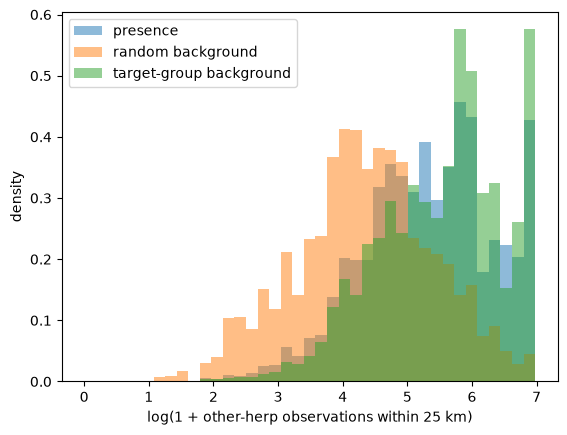

In [15]:
top = max(s_pres.max(), s_rand.max(), s_targ.max())
bins = np.linspace(0, top, 40)
for s, label in [(s_pres, "presence"), (s_rand, "random background"),
                 (s_targ, "target-group background")]:
    plt.hist(s, bins, density=True, alpha=0.5, label=label)
plt.xlabel("log(1 + other-herp observations within 25 km)")
plt.ylabel("density")
plt.legend()
plt.savefig("../docs/background_sampling.png", dpi=150, bbox_inches="tight")
plt.show()